# Búsqueda de hiperparámetros

**Qué responde:** ¿cuánto mejora el clasificador si, en vez de usar los hiperparámetros por defecto del baseline, se hace una **búsqueda acotada con presupuesto fijo**? Y, sobre todo, ¿esa mejora es **demostrable** o es ruido de la validación cruzada?

| Parte | Qué se busca | Dónde se decide |
|---|---|---|
| **A. Modelos** | `kNN`, `regresión logística`, `Random Forest` y `Naive Bayes`: hiperparámetros **y nivel de balanceo** (ninguno / pesos de clase / sobremuestreo / submuestreo, en el orden de la Tabla 3.4) | CV estratificada **solo sobre train** |
| **B. Regla comercial** | θ_def (fracción de superficie con defecto) y θ_col (matiz CIELAB bajo el cual el fruto es amarillo) para detectar **Fábrica** | Conjunto de **validación** (4.6.1, A.4) |
| **C. Modelo profundo** | Espacio de búsqueda de `E2_mvcnn` y `E5_multitarea` (AdamW, coseno, *early stopping*, focal loss γ/α, λ de la pérdida multitarea) | **Definido**, no ejecutado (requiere GPU e imágenes) |

**Protocolo (idéntico al baseline, para que la comparación sea pareada)**
- Misma partición congelada, mismos frutos, mismos pliegues y semillas (5 pliegues × 3 semillas).
- Todos los modelos reciben el **mismo número de candidatos** (`presupuesto_por_modelo`): ninguno gana por haber probado más.
- La selección usa **solo train**; **VAL** se calcula para cada candidato como control de optimismo; **TEST no se toca**.
- Ajustado vs. baseline: prueba t corregida para CV repetida (Nadeau & Bengio, 2003) con corrección de Holm.

In [2]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import busqueda_hiperparametros as bh, fe_experimentos as fx, extraer_features as ef, ingesta, particion
from src import regla_comercial as rc, estadistica as est, evidencia_hipotesis as eh
from src.fe_columnas import columnas_para

MODO_DEMO = False                      # <-- True solo para validar el flujo con imágenes sintéticas
EJECUTAR_BUSQUEDA = False              # True: corre la búsqueda (varios minutos). False: carga la última corrida guardada
PRESUPUESTO = None                     # None = el de configs/hiperparametros.yaml; p. ej. 8 para una prueba rápida
RAW  = ROOT / "data" / ("demo/raw" if MODO_DEMO else "raw")
PROC = ROOT / "data" / ("demo/processed" if MODO_DEMO else "processed")
cfg = bh.cargar_cfg_hp()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
COL = {"knn": "#1f77b4", "logreg": "#2ca02c", "rf": "#d62728", "gnb": "#9467bd"}
PAL = {"Extra": "#2e7d32", "Primera": "#7cb342", "Segunda": "#fbc02d", "Tercera": "#ef6c00", "Fabrica": "#7a1f2b"}
print("Presupuesto por modelo:", PRESUPUESTO or cfg["presupuesto_por_modelo"], "| modelos:", cfg["modelos"],
      "| selección por", cfg["metrica_seleccion"], "| variables:", cfg["conjunto_features"])

Presupuesto por modelo: 24 | modelos: ['knn', 'logreg', 'rf', 'gnb'] | selección por f1_macro | variables: A


## 0. Datos y control de atajo por sesión
Se generan los prerrequisitos que falten. Luego se mide **cuánto se puede acertar sin mirar el fruto**: un clasificador que solo conoce la sesión (lote × fecha) y predice su categoría más frecuente.

In [3]:
if not (PROC / "indice_frutos.csv").exists():   ingesta.main(RAW, PROC)
if not (PROC / "particion.csv").exists():       particion.main(PROC, forzar=False)
if not (PROC / "features_frutos.csv").exists(): ef.main(RAW, PROC, n_jobs=1)
df = fx.cargar_datos(PROC, ef.cargar_cfg())
tr, va, te = fx.dividir(df)
print(f"Frutos train/val/test: {len(tr)}/{len(va)}/{len(te)}  |  train por categoría: {tr['y'].value_counts().to_dict()}")

a = eh.atajo_sesion(df, columnas_para({"A"}))
print(f"Clasificador que SOLO conoce la sesión ({a['n_sesiones']} sesiones): F1 macro = {a['f1_macro_por_sesion']:.3f} | kappa = {a['kappa_por_sesion']:.3f} | recall Fábrica = {a['recall_fabrica_por_sesion']:.2f}")
print(f"Las variables de imagen identifican la sesión con exactitud {a['exactitud_sesion_desde_features']:.2f} (CV) | pureza media de categoría por sesión: {a['pureza_sesion']:.2f}")
print("Referencia: el dummy (clase mayoritaria) tiene F1 macro ≈ 0.07. Un modelo útil debe superar CLARAMENTE el F1 macro 'por sesión'.")

Frutos train/val/test: 359/76/76  |  train por categoría: {'Extra': 77, 'Primera': 71, 'Segunda': 71, 'Fabrica': 70, 'Tercera': 70}
Clasificador que SOLO conoce la sesión (4 sesiones): F1 macro = 0.733 | kappa = 0.753 | recall Fábrica = 1.00
Las variables de imagen identifican la sesión con exactitud 0.90 (CV) | pureza media de categoría por sesión: 0.88
Referencia: el dummy (clase mayoritaria) tiene F1 macro ≈ 0.07. Un modelo útil debe superar CLARAMENTE el F1 macro 'por sesión'.


## 1. Ejecutar la búsqueda (o cargar la última corrida)
Cada candidato se evalúa con 5 pliegues × 3 semillas sobre train y una vez sobre val. Todo queda registrado en `logs/hiperparametros_runs/<corrida>/` (`trials.csv` con todos los candidatos, `mejores.csv`, `comparacion_vs_baseline.csv`) y resumido en `logs/metrics_hiperparametros.txt`.

In [4]:
if EJECUTAR_BUSQUEDA:
    R = bh.ejecutar(PROC, cfg, presupuesto=PRESUPUESTO, verbose=True)
    RUN = R["dir"]
else:
    RUN = sorted((ROOT / "logs" / "hiperparametros_runs").glob("*"))[-1]
O = bh.cargar_run(RUN)
trials, mejores, comp, cv_mejores, cv_base = O["trials"], O["mejores"], O["comp"], O["cv_mejores"], O["cv_base"]
meta = O["cfg"]["meta"]
print("Corrida:", meta["run_id"], "| partición:", meta["huella_particion"], "| candidatos:", len(trials),
      "| por modelo:", trials.groupby("modelo").size().to_dict())
assert meta["huella_particion"] == __import__("src.particion", fromlist=["x"]).huella_particion(fx.cargar_particion(PROC)), "La corrida es de OTRA partición"
trials.head(3)

Corrida: 20261105_192724 | partición: 225c47198258 | candidatos: 96 | por modelo: {'gnb': 24, 'knn': 24, 'logreg': 24, 'rf': 24}


,cv_f1_macro_media,cv_f1_macro_std,val_f1_macro,cv_bal_acc_media,cv_bal_acc_std,val_bal_acc,cv_recall_pos_media,cv_recall_pos_std,val_recall_pos,cv_prauc_pos_media,...,params,p_n_neighbors,p_weights,p_p,p_C,p_n_estimators,p_max_depth,p_min_samples_leaf,p_max_features,p_var_smoothing
0,0.872341,0.044324,0.905521,0.872698,0.042951,0.907500,0.757143,0.128911,0.733333,0.961647,...,"{""n_neighbors"": 7, ""weights"": ""distance"", ""p"": 2}",7.0,distance,2.0,NaN,NaN,NaN,NaN,NaN,NaN
1,0.887963,0.035686,0.905718,0.887698,0.035421,0.906667,0.871429,0.108663,0.800000,0.887654,...,"{""n_neighbors"": 1, ""weights"": ""distance"", ""p"": 2}",1.0,distance,2.0,NaN,NaN,NaN,NaN,NaN,NaN
2,0.906659,0.040618,0.903512,0.906365,0.040647,0.907500,0.842857,0.111966,0.666667,0.964514,...,"{""n_neighbors"": 3, ""weights"": ""distance"", ""p"": 1}",3.0,distance,1.0,NaN,NaN,NaN,NaN,NaN,NaN


## 2. ¿Cuánto varía el desempeño dentro del espacio de búsqueda?
Cada punto es un candidato (F1 macro medio en CV sobre train). La **línea punteada** es el mismo modelo con hiperparámetros por defecto (baseline). Si casi todos los candidatos quedan cerca de la línea, **los hiperparámetros importan poco** y lo que limita es el dato; si hay mucha dispersión, vale la pena afinar.

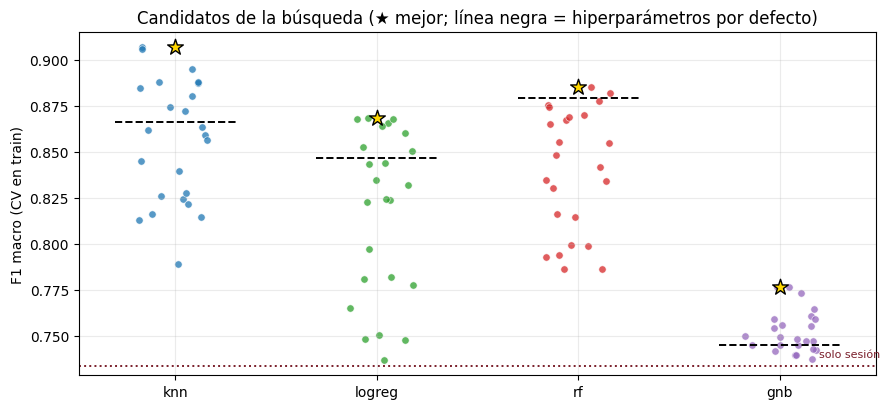

,min,median,max,defecto,rango
modelo,,,,,
gnb,0.737,0.749,0.776,0.745,0.039
knn,0.789,0.860,0.907,0.866,0.118
logreg,0.737,0.828,0.869,0.846,0.132
rf,0.786,0.845,0.885,0.879,0.099


In [5]:
modelos = [m for m in cfg["modelos"] if m in set(trials.modelo)]
base_cv = cv_base.groupby("config").f1_macro.mean()
dummy_ref = 0.07
fig, ax = plt.subplots(figsize=(9, 4.2))
rng = np.random.default_rng(0)
for i, m in enumerate(modelos):
    t = trials[trials.modelo == m]
    ax.scatter(i + rng.uniform(-.18, .18, len(t)), t.cv_f1_macro_media, s=28, alpha=.75, color=COL[m], edgecolor="white", lw=.5)
    mej = t.loc[t.cv_f1_macro_media.idxmax()]
    ax.scatter(i, mej.cv_f1_macro_media, s=140, marker="*", color="gold", edgecolor="k", zorder=5)
    ax.hlines(base_cv[f"BASE|{m}"], i - .3, i + .3, color="k", ls="--", lw=1.4)
ax.axhline(a["f1_macro_por_sesion"], color="#7a1f2b", ls=":", lw=1.4)
ax.text(len(modelos) - .5, a["f1_macro_por_sesion"] + .005, "solo sesión", color="#7a1f2b", ha="right", fontsize=8)
ax.set_xticks(range(len(modelos))); ax.set_xticklabels(modelos); ax.set_ylabel("F1 macro (CV en train)")
ax.set_title("Candidatos de la búsqueda (★ mejor; línea negra = hiperparámetros por defecto)")
plt.tight_layout(); plt.show()
resumen = trials.groupby("modelo").cv_f1_macro_media.agg(["min", "median", "max"]).round(3)
resumen["defecto"] = [round(base_cv[f"BASE|{m}"], 3) for m in resumen.index]
resumen["rango"] = (resumen["max"] - resumen["min"]).round(3)
display(resumen)

## 3. Presupuesto: ¿cuántos candidatos hacían falta?
Mejor F1 macro acumulado según el número de candidatos probados. Si la curva se aplana pronto, un presupuesto mayor no compra nada; si sigue subiendo, el espacio no se agotó.

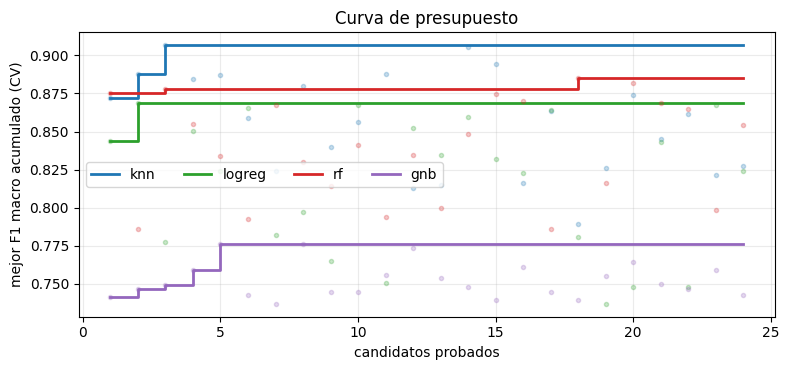

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for m in modelos:
    t = trials[trials.modelo == m].sort_values("iteracion")
    ax.step(t.iteracion + 1, t.cv_f1_macro_media.cummax(), where="post", color=COL[m], lw=2, label=m)
    ax.plot(t.iteracion + 1, t.cv_f1_macro_media, ".", color=COL[m], alpha=.25)
ax.set_xlabel("candidatos probados"); ax.set_ylabel("mejor F1 macro acumulado (CV)"); ax.legend(ncol=4)
ax.set_title("Curva de presupuesto"); plt.tight_layout(); plt.show()

## 4. Qué hiperparámetros importan
Para cada modelo, F1 macro de CV frente a cada hiperparámetro. Una tendencia clara (p. ej. *k* pequeño en kNN) indica un hiperparámetro relevante; una nube plana, uno irrelevante.

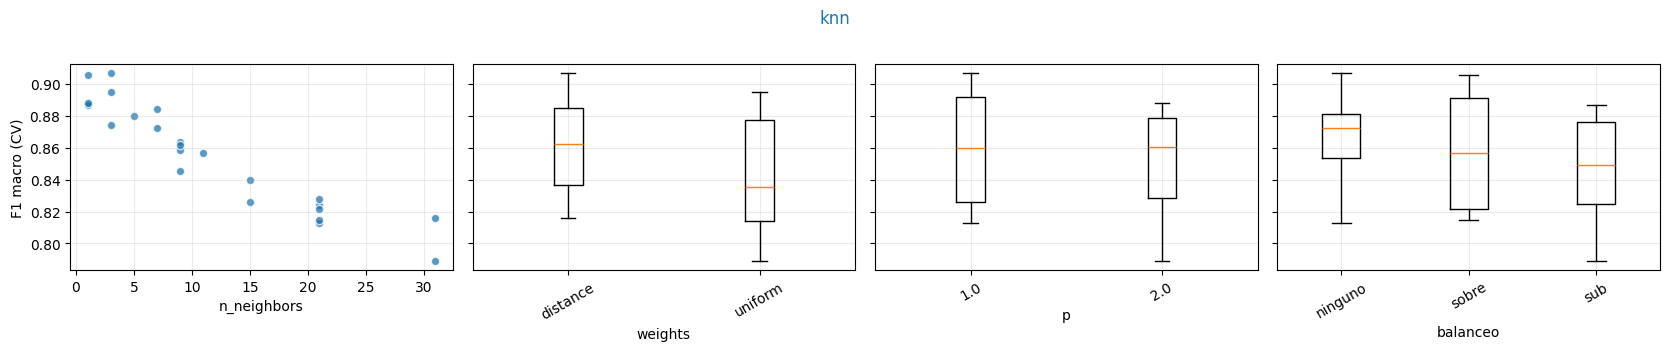

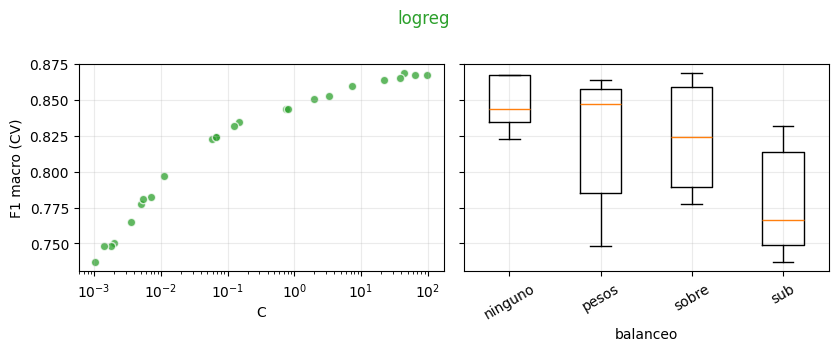

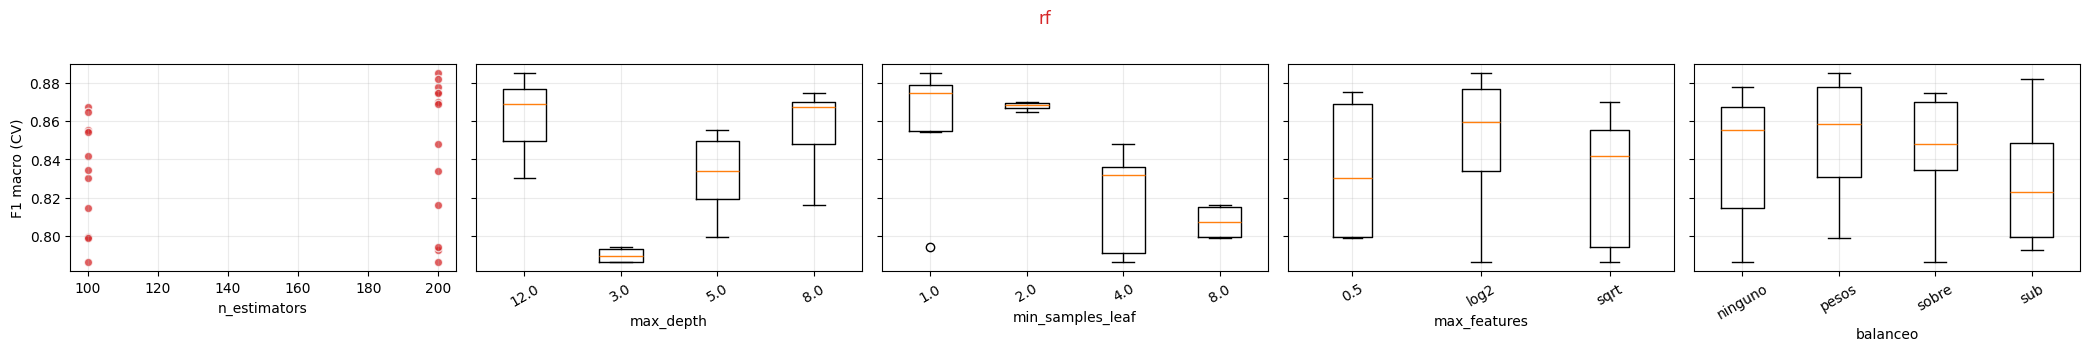

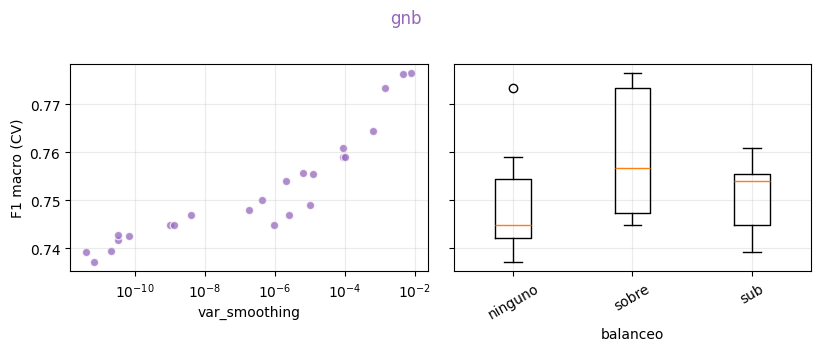

In [7]:
def panel(m, cols_num, cols_cat=()):
    t = trials[trials.modelo == m]
    n = len(cols_num) + len(cols_cat)
    fig, axs = plt.subplots(1, n, figsize=(4.2 * n, 3.4), sharey=True, squeeze=False)
    k = 0
    for c in cols_num:
        axs[0][k].scatter(t[c], t.cv_f1_macro_media, color=COL[m], alpha=.75, edgecolor="white")
        if c in ("p_C", "p_var_smoothing"): axs[0][k].set_xscale("log")
        axs[0][k].set_xlabel(c.replace("p_", "")); k += 1
    for c in cols_cat:
        g = t.assign(_c=t[c].astype(str)).groupby("_c").cv_f1_macro_media
        cats = list(g.groups)
        axs[0][k].boxplot([g.get_group(x) for x in cats], labels=cats)
        axs[0][k].tick_params(axis="x", rotation=30); axs[0][k].set_xlabel(c.replace("p_", "")); k += 1
    axs[0][0].set_ylabel("F1 macro (CV)"); fig.suptitle(m, y=1.02, color=COL[m]); plt.tight_layout(); plt.show()

if "knn" in modelos:    panel("knn", ["p_n_neighbors"], ["p_weights", "p_p", "balanceo"])
if "logreg" in modelos: panel("logreg", ["p_C"], ["balanceo"])
if "rf" in modelos:     panel("rf", ["p_n_estimators"], ["p_max_depth", "p_min_samples_leaf", "p_max_features", "balanceo"])
if "gnb" in modelos:    panel("gnb", ["p_var_smoothing"], ["balanceo"])

## 5. Mapa de calor (kNN: k × tipo de distancia)
Con espacio discreto pequeño se ve el efecto conjunto. Cada celda es el **mejor** F1 macro de CV entre los candidatos con esa combinación.

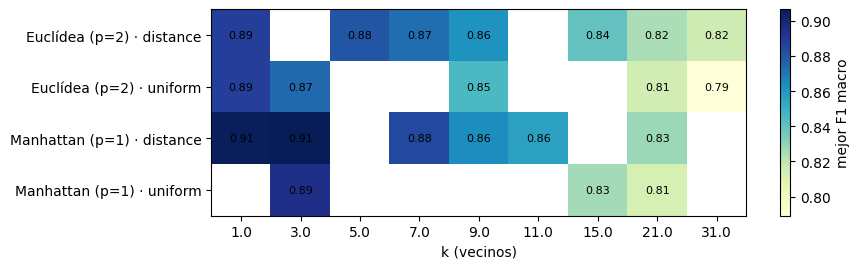

Celdas vacías = combinación no muestreada con el presupuesto fijo.


In [8]:
if "knn" in modelos:
    t = trials[trials.modelo == "knn"].assign(dist=lambda d: d.p_p.map({1: "Manhattan (p=1)", 2: "Euclídea (p=2)"}) + " · " + d.p_weights)
    h = t.pivot_table(index="dist", columns="p_n_neighbors", values="cv_f1_macro_media", aggfunc="max")
    fig, ax = plt.subplots(figsize=(9, 2.8))
    im = ax.imshow(h.values, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns); ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            v = h.values[i, j]
            if np.isfinite(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xlabel("k (vecinos)"); ax.grid(False); plt.colorbar(im, ax=ax, label="mejor F1 macro"); plt.tight_layout(); plt.show()
    print("Celdas vacías = combinación no muestreada con el presupuesto fijo.")

## 6. Balanceo en el orden de la Tabla 3.4
El nivel de balanceo se buscó junto con los hiperparámetros: **ninguno**, **pesos de clase** (solo logreg y RF), **sobremuestreo** y **submuestreo** (siempre dentro de `fit`, solo train). Se muestra el F1 macro y el de **Tercera** y **Fábrica**, las clases que motivan H5. *Focal loss y aumento dirigido (prioridades 3 y 4) requieren el modelo profundo.*

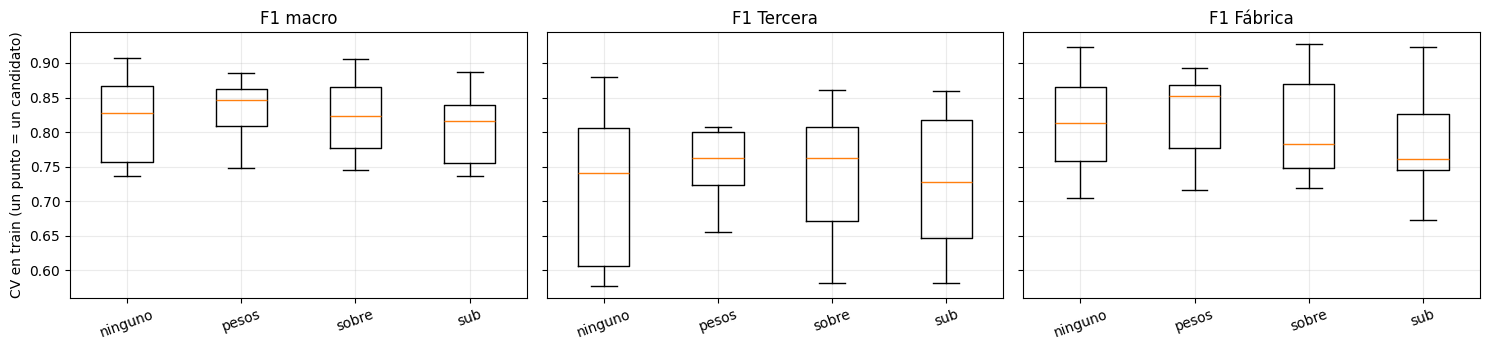

,F1 macro (median),F1 macro (max),F1 Tercera (median),F1 Tercera (max),F1 Fábrica (median),F1 Fábrica (max)
balanceo,,,,,,
ninguno,0.828,0.907,0.741,0.880,0.813,0.923
pesos,0.847,0.885,0.762,0.807,0.852,0.893
sobre,0.824,0.906,0.762,0.861,0.783,0.927
sub,0.816,0.887,0.728,0.860,0.761,0.923


Lectura: compara las medianas, no solo los máximos. Con ~24 candidatos por modelo, una diferencia de 1–2 puntos es ruido (ver desviación entre pliegues en §7).


In [9]:
b = trials.copy()
cols_f1 = [c for c in ("cv_f1_macro_media", "cv_f1_Tercera_media", "cv_f1_pos_media") if c in b.columns]
niveles = [n for n in cfg["balanceo"] if n in set(b.balanceo)]
fig, axs = plt.subplots(1, len(cols_f1), figsize=(5 * len(cols_f1), 3.6), sharey=True)
axs = np.atleast_1d(axs)
nom = {"cv_f1_macro_media": "F1 macro", "cv_f1_Tercera_media": "F1 Tercera", "cv_f1_pos_media": "F1 Fábrica"}
for ax, c in zip(axs, cols_f1):
    ax.boxplot([b.loc[b.balanceo == n, c].dropna() for n in niveles], labels=niveles)
    ax.set_title(nom[c]); ax.tick_params(axis="x", rotation=20)
axs[0].set_ylabel("CV en train (un punto = un candidato)"); plt.tight_layout(); plt.show()
tabla_bal = b.groupby("balanceo")[cols_f1].agg(["median", "max"]).round(3).reindex(niveles)
tabla_bal.columns = [f"{nom[a]} ({s})" for a, s in tabla_bal.columns]
display(tabla_bal)
print("Lectura: compara las medianas, no solo los máximos. Con ~24 candidatos por modelo, una diferencia de 1–2 puntos es ruido (ver desviación entre pliegues en §7).")

## 7. El mejor candidato de cada modelo
Se elige por F1 macro en CV (train). **VAL** es el control: si el F1 en VAL es mucho menor que en CV, la búsqueda sobreajustó el protocolo de validación cruzada.

,modelo,balanceo,CV F1 macro,CV kappa,CV F1 Fábrica,VAL F1 macro,VAL kappa,ajuste (s),params
0,knn,ninguno,0.907 ± 0.041,0.884,0.911,0.904,0.885,0.01,"{""n_neighbors"": 3, ""weights"": ""distance"", ""p"": 1}"
1,rf,pesos,0.885 ± 0.036,0.858,0.893,0.947,0.934,0.35,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa..."
2,logreg,sobre,0.869 ± 0.035,0.836,0.881,0.867,0.836,0.03,"{""C"": 45.01504909236857}"
3,gnb,sobre,0.776 ± 0.035,0.726,0.754,0.811,0.769,0.01,"{""var_smoothing"": 0.007845142231065359}"


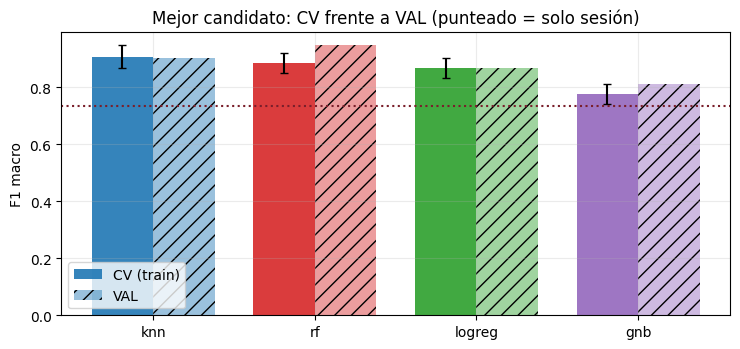

In [10]:
m = mejores.copy()
m["CV F1 macro"] = m.apply(lambda r: f"{r.cv_f1_macro_media:.3f} ± {r.cv_f1_macro_std:.3f}", axis=1)
m["CV kappa"] = m.cv_kappa_media.round(3)
m["CV F1 Fábrica"] = m.cv_f1_pos_media.round(3)
m["VAL F1 macro"] = m.val_f1_macro.round(3)
m["VAL kappa"] = m.val_kappa.round(3)
m["ajuste (s)"] = m.cv_fit_s_media.round(2)
display(m[["modelo", "balanceo", "CV F1 macro", "CV kappa", "CV F1 Fábrica", "VAL F1 macro", "VAL kappa", "ajuste (s)", "params"]])
fig, ax = plt.subplots(figsize=(7.5, 3.6)); x = np.arange(len(m)); w = .38
ax.bar(x - w/2, m.cv_f1_macro_media, w, yerr=m.cv_f1_macro_std, capsize=3, color=[COL[k] for k in m.modelo], alpha=.9, label="CV (train)")
ax.bar(x + w/2, m.val_f1_macro, w, color=[COL[k] for k in m.modelo], alpha=.45, hatch="//", label="VAL")
ax.axhline(a["f1_macro_por_sesion"], color="#7a1f2b", ls=":"); ax.set_xticks(x); ax.set_xticklabels(m.modelo)
ax.set_ylabel("F1 macro"); ax.set_title("Mejor candidato: CV frente a VAL (punteado = solo sesión)"); ax.legend(); plt.tight_layout(); plt.show()

## 8. ¿Ajustar mejora de forma demostrable? (mejor candidato vs. baseline)
Diferencia **pareada** por pliegue entre el mejor candidato y el mismo modelo con hiperparámetros por defecto. `veredicto` dice *mejora* solo si el p ajustado por Holm es < 0,05.

> **Cuidado con el optimismo:** el mejor de 24 candidatos se eligió *mirando* estos mismos pliegues, así que su diferencia con el baseline está sesgada hacia arriba. Una mejora honesta se confirma en VAL (y, al final, en TEST una sola vez).

,modelo,base_media,ajustado_media,dif_media,pliegues_mejoran_pct,p,p_holm,veredicto
0,gnb,0.745,0.776,0.032,53.333,0.475,0.889,sin evidencia
1,knn,0.866,0.907,0.041,86.667,0.014,0.056,sin evidencia
2,logreg,0.846,0.869,0.022,80.000,0.227,0.680,sin evidencia
3,rf,0.879,0.885,0.006,53.333,0.444,0.889,sin evidencia


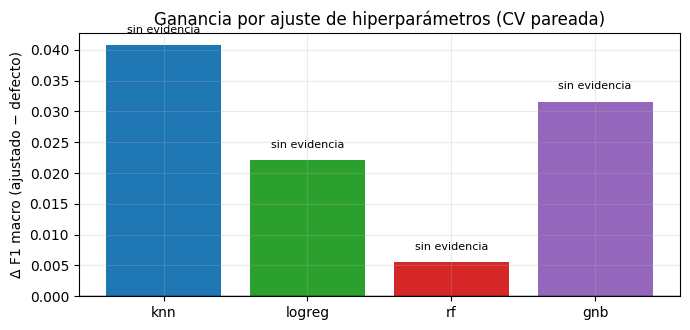

Control en VAL (76 frutos: un fruto = 1,3 puntos de exactitud):


,VAL baseline (defecto),VAL ajustado,diferencia
modelo,,,
gnb,0.811,0.811,0.000
knn,0.908,0.904,-0.004
logreg,NaN,0.867,NaN
rf,NaN,0.947,NaN


In [11]:
c = comp.copy()
display(c[c.metrica == "f1_macro"][["modelo", "base_media", "ajustado_media", "dif_media", "pliegues_mejoran_pct", "p", "p_holm", "veredicto"]].round(3).reset_index(drop=True))
f1 = c[c.metrica == "f1_macro"].set_index("modelo").reindex(modelos)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(f1)), f1.dif_media, color=[COL[k] for k in f1.index])
for i, (k, r) in enumerate(f1.iterrows()):
    ax.text(i, r.dif_media + (.002 if r.dif_media >= 0 else -.006), r.veredicto, ha="center", fontsize=8)
ax.axhline(0, color="k", lw=1); ax.set_xticks(range(len(f1))); ax.set_xticklabels(f1.index)
ax.set_ylabel("Δ F1 macro (ajustado − defecto)"); ax.set_title("Ganancia por ajuste de hiperparámetros (CV pareada)"); plt.tight_layout(); plt.show()
# Control en VAL
base_val = pd.read_csv(sorted((ROOT / "logs/baseline_runs").glob("*/resultados.csv"))[-1])
bv = base_val[(base_val.variante == "BASE") & (base_val.modelo.isin(modelos))].set_index("modelo").val_f1_macro
ctl = pd.DataFrame({"VAL baseline (defecto)": bv, "VAL ajustado": mejores.set_index("modelo").val_f1_macro}).assign(
    diferencia=lambda d: d["VAL ajustado"] - d["VAL baseline (defecto)"]).round(3)
print("Control en VAL (76 frutos: un fruto = 1,3 puntos de exactitud):"); display(ctl)

## 9. Mejor configuración global: matriz de confusión y metas de la tesis
Se toma el mejor modelo por CV (no por VAL). Con las **predicciones en VAL** se calculan los indicadores de la hipótesis general (F1 macro ≥ 0,90, recall de Fábrica ≥ 0,90, κ ≥ 0,80) con **IC95 % por bootstrap pareado (B = 1000)**; la regla de la tesis exige que el **límite inferior** del IC cumpla el umbral.

> Es evidencia **informativa**: modelo clásico, validación (no TEST) y, si hay atajo de sesión, posiblemente optimista.

In [12]:
g = mejores.sort_values("cv_f1_macro_media", ascending=False).iloc[0]
print(f"Mejor global por CV: {g.modelo} | balanceo = {g.balanceo} | {g.params}")
cm = O["cms"][g.candidato]; lab = cm["labels"]
display(pd.DataFrame(cm["matriz"], index=[f"real {x}" for x in lab], columns=[f"pred {x}" for x in lab]))
# reajustar el mejor con train y predecir VAL (mismos pasos que la búsqueda)
cols = [c for c in columnas_para(set(cfg["conjunto_features"].split("+"))) if tr[c].notna().any()]
cand = json.loads(g.params); cand["balanceo"] = g.balanceo
pipe = bh.construir(g.modelo, cand, cols, cfg["conjunto_features"], cfg["semillas"][0], {**ef.cargar_cfg(), "modelo_params": {}})
pipe.fit(tr[cols], tr["y"].to_numpy()); pred = pipe.predict(va[cols]); y = va["y"].to_numpy()
metas = [("F1 macro", lambda a, p: est.metricas_tesis(a, p)["f1_macro"], .90),
         ("Recall de Fábrica", lambda a, p: est.recall_clase(a, p, "Fabrica"), .90),
         ("Kappa de Cohen", lambda a, p: est.kappa_cohen(a, p), .80)]
filas = []
for nombre, f, umbral in metas:
    ic = est.bootstrap_pareado(y, pred, metrica=f, B=1000)
    filas.append(dict(indicador=nombre, meta=umbral, estimado=ic["estimado"], IC95_inf=ic["ic_inf"], IC95_sup=ic["ic_sup"],
                      lectura=est.verifica_umbral_ic(ic, umbral)))
display(pd.DataFrame(filas).round(3))
print("F1 por clase en VAL:", {k: round(est.f1_clase(y, pred, k), 3) for k in ["Extra", "Primera", "Segunda", "Tercera", "Fabrica"]})

Mejor global por CV: knn | balanceo = ninguno | {"n_neighbors": 3, "weights": "distance", "p": 1}


,pred Extra,pred Fabrica,pred Primera,pred Segunda,pred Tercera
real Extra,15,0,0,1,0
real Fabrica,1,10,2,0,2
real Primera,0,0,14,0,1
real Segunda,0,0,0,15,0
real Tercera,0,0,0,0,15


,indicador,meta,estimado,IC95_inf,IC95_sup,lectura
0,F1 macro,0.9,0.904,0.828,0.964,estimado >= umbral pero IC inf < umbral
1,Recall de Fábrica,0.9,0.667,0.417,0.900,no cumple
2,Kappa de Cohen,0.8,0.885,0.801,0.965,cumple (IC inf >= umbral)


F1 por clase en VAL: {'Extra': 0.938, 'Primera': 0.903, 'Segunda': 0.968, 'Tercera': 0.909, 'Fabrica': 0.8}


## 10. Parte B — calibración de los umbrales de la regla comercial (θ_def, θ_col)
La regla jerárquica (Figura 4.2) manda a **Fábrica** si el defecto supera θ_def **o** si el matiz CIELAB queda por debajo de θ_col (amarillo). Según 4.6.1 (A.4), ambos se ajustan sobre **validación** y se **congelan** antes de la recolección definitiva. Aquí se recorre la rejilla y se mide el **recall y F1 de Fábrica** de la regla sobre los atributos extraídos de la imagen (sin modelo aprendido).

*Es la parte "atributos + regla" de la comparación E2/H6, con extracción clásica; la versión profunda queda pendiente.*

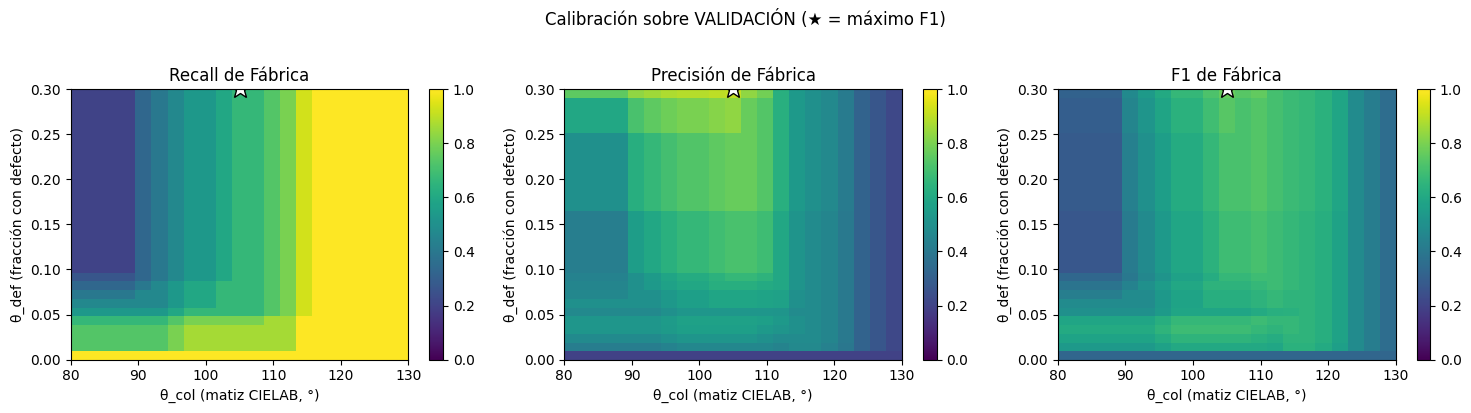

Máximo F1 de Fábrica en VAL: θ_def = 0.30, θ_col = 105.0° -> recall 0.67, precisión 0.91, F1 0.77
Mejor F1 con recall ≥ 0.9: θ_def = 0.23, θ_col = 115.0° -> recall 0.93, precisión 0.54, F1 0.68
Con los valores por defecto del repositorio (θ_def = 0.1, θ_col = 103.0°): recall 0.60, precisión 0.69


In [13]:
u = cfg["umbrales_regla"]
rej_def = np.arange(u["theta_def"]["min"], u["theta_def"]["max"] + 1e-9, u["theta_def"]["paso"])
rej_col = np.arange(u["theta_col"]["min"], u["theta_col"]["max"] + 1e-9, u["theta_col"]["paso"])
yv = (va["y"] == "Fabrica").to_numpy()
G = rc.calibrar_umbrales(va, yv, rej_def, rej_col)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (c, tit) in zip(axs, [("recall", "Recall de Fábrica"), ("precision", "Precisión de Fábrica"), ("f1", "F1 de Fábrica")]):
    h = G.pivot(index="theta_def", columns="theta_col", values=c)
    im = ax.imshow(h.values, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1,
                   extent=[h.columns.min(), h.columns.max(), h.index.min(), h.index.max()])
    ax.set_title(tit); ax.set_xlabel("θ_col (matiz CIELAB, °)"); ax.set_ylabel("θ_def (fracción con defecto)"); ax.grid(False)
    plt.colorbar(im, ax=ax)
mejor = G.sort_values(["f1", "recall"], ascending=False).iloc[0]
cumple = G[G.recall >= u["recall_fabrica_minimo"]].sort_values("f1", ascending=False)
for ax in axs: ax.plot(mejor.theta_col, mejor.theta_def, "w*", ms=14, mec="k")
plt.suptitle("Calibración sobre VALIDACIÓN (★ = máximo F1)", y=1.02); plt.tight_layout(); plt.show()
print(f"Máximo F1 de Fábrica en VAL: θ_def = {mejor.theta_def:.2f}, θ_col = {mejor.theta_col:.1f}° -> recall {mejor.recall:.2f}, precisión {mejor.precision:.2f}, F1 {mejor.f1:.2f}")
if len(cumple):
    c0 = cumple.iloc[0]; print(f"Mejor F1 con recall ≥ {u['recall_fabrica_minimo']}: θ_def = {c0.theta_def:.2f}, θ_col = {c0.theta_col:.1f}° -> recall {c0.recall:.2f}, precisión {c0.precision:.2f}, F1 {c0.f1:.2f}")
else:
    print(f"Ningún par de la rejilla alcanza recall ≥ {u['recall_fabrica_minimo']}: la regla con estos atributos extraídos NO llega a la meta de recall de Fábrica.")
ref = rc.UmbralesRegla(**{k: v for k, v in ef.cargar_cfg()["dominio"].items() if k == "theta_def"}, theta_col=ef.cargar_cfg()["dominio"]["hue_amarillo_max"])
p = rc.es_fabrica_df(va, ref.theta_def, ref.theta_col)
print(f"Con los valores por defecto del repositorio (θ_def = {ref.theta_def}, θ_col = {ref.theta_col}°): recall {(p & yv).sum() / yv.sum():.2f}, precisión {(p & yv).sum() / max(p.sum(), 1):.2f}")

### Estabilidad de los umbrales (¿dependen de la muestra de validación?)
Se repite la calibración sobre remuestreos bootstrap de VAL y se mira cuánto se mueve el par óptimo. Si el óptimo salta, los umbrales **no están identificados** con tan pocos frutos y deben fijarse con el panel.

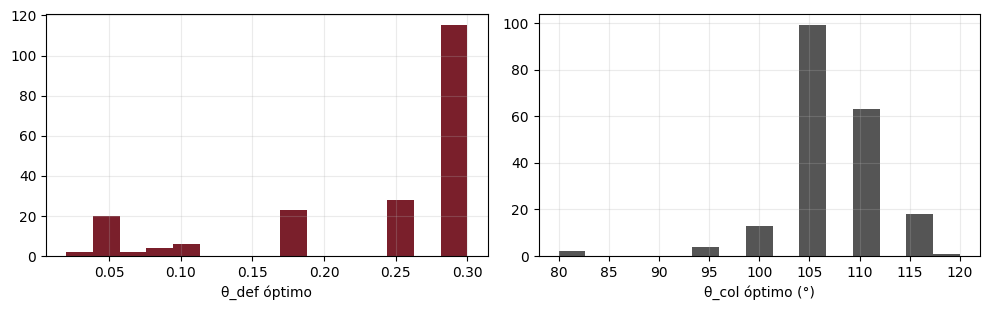

      theta_def  theta_col
mean       0.24     106.78
std        0.09       4.98
min        0.02      80.00
max        0.30     120.00


In [14]:
rng = np.random.default_rng(0); opt = []
rej_def2, rej_col2 = rej_def[::2], rej_col[::2]
for _ in range(200):
    i = rng.integers(0, len(va), len(va)); s = va.iloc[i]
    gb = rc.calibrar_umbrales(s, (s["y"] == "Fabrica").to_numpy(), rej_def2, rej_col2)
    o = gb.sort_values(["f1", "recall"], ascending=False).iloc[0]; opt.append((o.theta_def, o.theta_col))
opt = pd.DataFrame(opt, columns=["theta_def", "theta_col"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].hist(opt.theta_def, bins=15, color="#7a1f2b"); axs[0].set_xlabel("θ_def óptimo")
axs[1].hist(opt.theta_col, bins=15, color="#555"); axs[1].set_xlabel("θ_col óptimo (°)")
plt.tight_layout(); plt.show()
print(opt.describe().loc[["mean", "std", "min", "max"]].round(2))

## 11. Parte C — espacio de búsqueda del modelo profundo (definido, no ejecutado)

In [16]:
ep = cfg["espacio_profundo"]
filas = [("Presupuesto por configuración", ep["presupuesto_por_configuracion"], "Tabla 4.2: presupuesto de cómputo fijo"),
         ("Optimizador / scheduler", f"{ep['optimizador']} / {ep['scheduler']}", "4.6.1, A.3"),
         ("Early stopping", f"monitor = {ep['early_stopping']['monitor']}, paciencia ∈ {ep['early_stopping']['paciencia']}", "4.6.1, A.3"),
         ("Tasa de aprendizaje", f"log-uniforme [{ep['lr']['min']:g}, {ep['lr']['max']:g}]", "E2 y E5"),
         ("Weight decay", f"log-uniforme [{ep['weight_decay']['min']:g}, {ep['weight_decay']['max']:g}]", "E2 y E5"),
         ("Batch size", ep["batch_size"], "E2 y E5"),
         ("Focal loss", f"γ ∈ {ep['focal_loss']['gamma']}, α ∈ {ep['focal_loss']['alpha']}", "Tabla 3.4, prioridad 3 (E3)"),
         ("Pooling de vistas", ep["pooling_vistas"], "solo E2_mvcnn"),
         ("λ de la pérdida multitarea", ep["lambdas_multitarea"], "ecuación (3), solo E5"),
         ("Aumento de datos", ep["aumento"], "Tabla 3.4, prioridad 4 (E3)")]
display(pd.DataFrame(filas, columns=["Hiperparámetro", "Espacio", "Fuente en la tesis"]))
print("Cuando haya GPU: reutilizar bh.candidatos() con este espacio, la misma partición, 3 semillas y la misma tabla de comparación pareada.")

,Hiperparámetro,Espacio,Fuente en la tesis
0,Presupuesto por configuración,12,Tabla 4.2: presupuesto de cómputo fijo
1,Optimizador / scheduler,adamw / cosine,"4.6.1, A.3"
2,Early stopping,"monitor = val_loss, paciencia ∈ [5, 8]","4.6.1, A.3"
3,Tasa de aprendizaje,"log-uniforme [1e-05, 0.001]",E2 y E5
4,Weight decay,"log-uniforme [1e-05, 0.1]",E2 y E5
5,Batch size,"[8, 16]",E2 y E5
6,Focal loss,"γ ∈ [0.0, 1.0, 2.0, 3.0], α ∈ [0.25, 0.5, 0.75]","Tabla 3.4, prioridad 3 (E3)"
7,Pooling de vistas,"[max, mean]",solo E2_mvcnn
8,λ de la pérdida multitarea,"{'lambda_seg': [0.5, 1.0], 'lambda_col': [0.5,...","ecuación (3), solo E5"
9,Aumento de datos,"[ninguno, geometrico, geometrico_color_suave]","Tabla 3.4, prioridad 4 (E3)"


Cuando haya GPU: reutilizar bh.candidatos() con este espacio, la misma partición, 3 semillas y la misma tabla de comparación pareada.


## 12. Decisiones (completar con datos reales)
| # | Pregunta | Evidencia | Decisión |
|---|---|---|---|
| 1 | ¿La categoría se puede adivinar con solo la sesión? ¿Qué tan por encima de ese piso están los modelos? | §0, §7 | |
| 2 | ¿Qué modelo e hiperparámetros se llevan a la comparación final? | §7 | |
| 3 | ¿El ajuste mejora de forma demostrable (p Holm < 0,05) y se confirma en VAL? | §8 | |
| 4 | ¿Qué nivel de balanceo conviene (Tabla 3.4) y para qué clase? | §6 | |
| 5 | ¿Los umbrales θ_def y θ_col son estables? ¿Se fijan con el panel en el piloto? | §10 | |
| 6 | ¿Se alcanzan las metas de la hipótesis general con IC inferior ≥ umbral? | §9 | |